# Figure 3 Supplement 1: Stopping-model comparison and parameter recovery

Each alternative changes one part of the main stopping model and is fit to the
same trials (`scripts/run_stopping_fits.py`; one fit per subject, jointly over
that subject's six OL blocks, so the comparison uses all six blocks rather than
only the low-SNR blocks 1–3 shown in the other Figure 3 supplements).

- **A — total ΔAIC** (alternative − main, summed over subjects; positive =
  main model better), log scale.
- **B — per subject:** the fraction of subjects for whom the main model is
  better by more than 2 AIC units, the two are within 2, or the alternative is
  better by more than 2.
- **C, D — parameter recovery** (`scripts/run_stopping_bootstrap.py`): each OL
  subject was simulated `NUM_REPS` = 10 times from their main fit, on their
  real trial structure (same blocks, trial counts, SNRs and step statistics),
  and each simulated data set was refit with the same model, from a single
  start at the knee that generated it (the main fits use three starting knees). Each cell:
  Spearman correlation across subjects between the parameter used to simulate
  and the median of its 10 refits. **C:** parameters fit separately in each
  block (bound plateau, bound variability = CV of the trial-to-trial bound,
  early-guess, lapse and pure-guess rates), OL low-SNR blocks 1–3; subject-blocks
  whose plateau sits at a fit limit or above the screen edge (0.75) are left out (counts printed). **D:**
  parameters shared across a subject's blocks (start height = bound at step 1
  relative to the plateau, log; time of the transition to the plateau; slope of the
  bound after the transition, log units per step; sensory noise; probability of a
  one-step non-decision time vs. two steps). Refits that did not converge are
  left out (counts printed). The table also gives each parameter's median
  per-subject spread of refits (10th–90th percentile, relative to the
  simulated value), used for error bars elsewhere.

  **Text only:** the same comparison for cohort 2 (MX, mixed SNR; every variant was also fit to its
  three blocks), printed as a second table.

  **Text only:** the fitted per-block parameters themselves (main fits, OL blocks 1–3),
  median [IQR] across subjects, with the same edge-fit exclusions; e.g. the bound
  variability (CV) cited in the Results.

Main model: the bound starts high, falls to a plateau at a time fit for each
subject, then declines slowly; this time course is the same in all of a
subject's blocks. The plateau, the bound's trial-to-trial variability and the
early-guess, lapse and pure-guess rates are fit per block; sensory noise and the
non-decision time (1 or 2 steps) per subject.

Alternatives (fit variant in parentheses):

- **Constant bound** (`flat`): no time course.
- **Constant bound, more guessing early** (`flat_guess_tc`): instead of a high
  early bound, a guess rate that changes over the trial.
- **Bound falls at fixed times** (`knots`): the bound
  changes linearly between fixed steps 1, 6 and 16 instead of falling to its
  plateau at a fitted time.
- **Fixed bound after transition** (`knee_flat`): the bound stays at the
  plateau after the transition.
- **No bound variability** (`fixed_cv`): the trial-to-trial CV of the bound
  fixed at 0.03, the lower limit of the fitted CV.
- **Separate bound time course per block** (`per_block_tc`) or **per SNR**
  (`tc_by_snr`).
- **No sensory noise** (`no_noise`).
- **Non-decision time up to 3 steps** (`ndt123`): the main model allows 1 or 2 steps
  (the key press 200–600 ms after the committed position appeared); this one also allows 3.
- **Same guess and lapse rates in all blocks** (`shared_rates`; pure-guess
  rates also shared).

In [1]:
import sys
sys.path.insert(0, '..')


import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import pandas as pd
import scipy.stats

from pigeon.pathDefaults import DATA_DIR, FIGURES_DIR
from pigeon.plotting import CM, FS_INSET, CONDITION_LABELS, MODEL_COLOR, add_panel_label, use_figure_style
from pigeon.stopping import get_plateau_edge_fit

PROCESSED = DATA_DIR

In [2]:
TASK = 'OL'   # cohort shown in the figure and in the parameter tables below
TASKS = {'OL': 'Cohort 1 (blocked SNR)', 'MX': 'Cohort 2 (mixed SNR; text only)'}
AIC_MARGIN = 2.0
VARIANTS = {   # file suffix: label
    'flat': 'Constant bound',
    'flat_guess_tc': 'Constant bound, more guessing early',
    'knots': 'Bound falls at fixed times',
    'knee_flat': 'Fixed bound after transition',
    'fixed_cv': 'No bound variability',
    'per_block_tc': 'Separate bound time course per block',
    'tc_by_snr': 'Separate bound time course per SNR',
    'no_noise': 'No sensory noise',
    'ndt123': 'Non-decision time up to 3 steps',
    'shared_rates': 'Same guess and lapse rates in all blocks',
}

def _per_subject(variant, task):
    f = pd.read_pickle(PROCESSED / f'stopping_fits_{variant}.pkl')
    s = f[f.task == task].groupby('subject_index').first()
    return pd.DataFrame({'aic': 2 * s.nll + 2 * s.n_params, 'n_params': s.n_params, 'success': s.success})

comp_by_task = {}
for task, task_label in TASKS.items():
    main = _per_subject('main', task)
    rows = []
    for v, label in VARIANTS.items():
        alt = _per_subject(v, task)
        d = (alt.aic - main.aic).dropna()
        rows.append({'variant': v, 'label': label, 'subjects': len(d), 'ΔAIC total': d.sum(),
                     'ΔAIC median': d.median(), 'Δ params / subject': int((alt.n_params - main.n_params).median()),
                     'main better': np.mean(d > AIC_MARGIN), 'within 2': np.mean(d.abs() <= AIC_MARGIN),
                     'alternative better': np.mean(d < -AIC_MARGIN),
                     'not converged (alt / main)': f'{int((~alt.success).sum())} / {int((~main.success).sum())}'})
    comp_by_task[task] = pd.DataFrame(rows).set_index('variant')
    print(task_label)
    display(comp_by_task[task].round(3))
comp = comp_by_task[TASK]

Cohort 1 (blocked SNR)


,label,subjects,ΔAIC total,ΔAIC median,Δ params / subject,main better,within 2,alternative better,not converged (alt / main)
variant,,,,,,,,,
flat,Constant bound,60,4787.990,69.185,-3,0.967,0.033,0.000,0 / 0
flat_guess_tc,"Constant bound, more guessing early",60,3974.447,53.823,-1,0.967,0.000,0.033,0 / 0
knots,Bound falls at fixed times,60,1344.319,14.985,-1,0.817,0.150,0.033,0 / 0
knee_flat,Fixed bound after transition,60,446.913,1.892,-1,0.500,0.433,0.067,0 / 0
fixed_cv,No bound variability,60,1759.589,20.810,-6,0.750,0.050,0.200,0 / 0
per_block_tc,Separate bound time course per block,60,1209.972,22.284,15,0.933,0.067,0.000,0 / 0
tc_by_snr,Separate bound time course per SNR,60,87.729,3.195,3,0.583,0.150,0.267,0 / 0
no_noise,No sensory noise,60,1286.867,13.166,-1,0.767,0.117,0.117,0 / 0
ndt123,Non-decision time up to 3 steps,60,337.348,7.079,1,0.633,0.183,0.183,0 / 0


Cohort 2 (mixed SNR; text only)


,label,subjects,ΔAIC total,ΔAIC median,Δ params / subject,main better,within 2,alternative better,not converged (alt / main)
variant,,,,,,,,,
flat,Constant bound,60,2026.891,21.020,-3,0.917,0.050,0.033,0 / 0
flat_guess_tc,"Constant bound, more guessing early",60,2042.397,22.906,-1,0.967,0.017,0.017,0 / 0
knots,Bound falls at fixed times,60,574.888,6.185,-1,0.750,0.217,0.033,0 / 0
knee_flat,Fixed bound after transition,60,161.684,0.946,-1,0.400,0.467,0.133,0 / 0
fixed_cv,No bound variability,60,2216.682,12.832,-3,0.750,0.133,0.117,2 / 0
per_block_tc,Separate bound time course per block,60,568.473,9.882,6,0.933,0.067,0.000,0 / 0
tc_by_snr,Separate bound time course per SNR,60,268.760,4.914,3,0.733,0.233,0.033,0 / 0
no_noise,No sensory noise,60,627.198,7.163,-1,0.617,0.183,0.200,0 / 0
ndt123,Non-decision time up to 3 steps,60,267.023,1.998,1,0.483,0.317,0.200,1 / 0


In [3]:
BLOCKS = ['B1', 'B2', 'B3']
BLOCK_TITLES = {f'B{b}': CONDITION_LABELS[b] for b in (1, 2, 3)}
PER_BLOCK = {'bound_scale': 'Bound plateau', 'bound_cv': 'Bound variability', 'guess_rate': 'Early-guess rate',
             'lapse_rate': 'Lapse rate', 'anticipation_rate': 'Pure-guess rate'}
SHARED = {'log_h_start': 'Start height', 'knee': 'Time of transition', 'late_slope': 'Slope after transition',
          'sensory_std': 'Sensory noise', 'ndt_p1': 'P(1-step non-decision time)'}

boot = pd.read_pickle(PROCESSED / 'stopping_bootstrap.pkl')
boot = boot[boot.task == 'OL']
n_fail = boot[~boot.success].groupby(['subject_index', 'rep']).ngroups
print(f'{n_fail} of {boot.groupby(["subject_index", "rep"]).ngroups} OL refits did not converge (left out)')
boot = boot[boot.success]
true = boot.groupby(['subject_index', 'group']).first()[[f'{p}_true' for p in {**PER_BLOCK, **SHARED}]]
fit = boot.groupby(['subject_index', 'group'])[[f'{p}_fit' for p in {**PER_BLOCK, **SHARED}]]
med, q10, q90 = fit.median(), fit.quantile(0.1), fit.quantile(0.9)

lim = pd.DataFrame({'bound_scale': true.bound_scale_true, 'group': true.index.get_level_values('group'),
                    'subject_index': true.index.get_level_values('subject_index')})
l_lim = get_plateau_edge_fit(lim).to_numpy() & true.index.get_level_values('group').isin(BLOCKS)
print(f'per-block parameters: left out {int(l_lim.sum())} subject-blocks with an edge fit (plateau at a fit limit or > 0.75): '
      f'{list(true.index[l_lim])}')

def _rho(t, m):
    ok = np.isfinite(t) & np.isfinite(m)
    return scipy.stats.spearmanr(t[ok], m[ok]).statistic, int(ok.sum())

def _spread(t, lo, hi):
    return np.median((hi - lo) / np.abs(t))

rows, rho_block = [], pd.DataFrame(index=list(PER_BLOCK), columns=BLOCKS, dtype=float)
for p, label in PER_BLOCK.items():
    for b in BLOCKS:
        l = (true.index.get_level_values('group') == b) & ~l_lim
        r, n = _rho(true.loc[l, f'{p}_true'], med.loc[l, f'{p}_fit'])
        rho_block.loc[p, b] = r
        rows.append({'parameter': label, 'block': b, 'subjects': n, 'Spearman rho': r,
                     'median relative 10-90% spread': _spread(true.loc[l, f'{p}_true'], q10.loc[l, f'{p}_fit'],
                                                              q90.loc[l, f'{p}_fit'])})
first = true.groupby(level='subject_index').head(1).index    # shared parameters: one row per subject
rho_shared = pd.Series(index=list(SHARED), dtype=float)
for p, label in SHARED.items():
    r, n = _rho(true.loc[first, f'{p}_true'], med.loc[first, f'{p}_fit'])
    rho_shared[p] = r
    rows.append({'parameter': label, 'block': 'all', 'subjects': n, 'Spearman rho': r,
                 'median relative 10-90% spread': _spread(true.loc[first, f'{p}_true'], q10.loc[first, f'{p}_fit'],
                                                          q90.loc[first, f'{p}_fit'])})
display(pd.DataFrame(rows).round(3))

2 of 600 OL refits did not converge (left out)
per-block parameters: left out 13 subject-blocks with an edge fit (plateau at a fit limit or > 0.75): [(6, 'B2'), (13, 'B3'), (22, 'B2'), (23, 'B3'), (38, 'B3'), (39, 'B3'), (44, 'B2'), (44, 'B3'), (51, 'B1'), (51, 'B2'), (55, 'B3'), (59, 'B1'), (59, 'B2')]


,parameter,block,subjects,Spearman rho,median relative 10-90% spread
0,Bound plateau,B1,58,0.985,0.286
1,Bound plateau,B2,55,0.997,0.179
2,Bound plateau,B3,54,0.988,0.261
3,Bound variability,B1,58,0.973,0.580
4,Bound variability,B2,55,0.958,0.468
5,Bound variability,B3,54,0.955,0.642
6,Early-guess rate,B1,58,0.991,0.861
7,Early-guess rate,B2,55,0.959,1.185
8,Early-guess rate,B3,54,0.903,2.334
9,Lapse rate,B1,58,0.971,1.115


In [4]:
# Text only: fitted per-block parameters (main fits), median [IQR] across subjects, blocks 1-3.
fits_main = pd.read_pickle(PROCESSED / 'stopping_fits_main.pkl')
fits_main = fits_main[(fits_main.task == TASK) & fits_main.group.isin(BLOCKS)]
l_lim_main = get_plateau_edge_fit(fits_main).to_numpy()
print(f'fitted values: left out {int(l_lim_main.sum())} subject-blocks with an edge fit (plateau at a fit limit or > 0.75)')
fits_main = fits_main[~l_lim_main]
q = fits_main.groupby('group')[list(PER_BLOCK)].quantile([0.25, 0.5, 0.75]).unstack()
fitted = pd.DataFrame({label: [f'{q[p, 0.5][b]:.3f} [{q[p, 0.25][b]:.3f}, {q[p, 0.75][b]:.3f}]' for b in BLOCKS]
                       for p, label in PER_BLOCK.items()}, index=BLOCKS).T
fitted['subjects'] = ''
fitted.loc[:, 'subjects'] = ', '.join(f'{b}: {n}' for b, n in fits_main.groupby('group').size().items())
display(fitted)


fitted values: left out 13 subject-blocks with an edge fit (plateau at a fit limit or > 0.75)


,B1,B2,B3,subjects
Bound plateau,"0.197 [0.110, 0.364]","0.422 [0.284, 0.559]","0.304 [0.203, 0.446]","B1: 58, B2: 55, B3: 54"
Bound variability,"0.442 [0.257, 0.774]","0.335 [0.204, 0.524]","0.373 [0.113, 0.568]","B1: 58, B2: 55, B3: 54"
Early-guess rate,"0.037 [0.005, 0.226]","0.009 [0.000, 0.030]","0.004 [0.000, 0.040]","B1: 58, B2: 55, B3: 54"
Lapse rate,"0.078 [0.000, 0.211]","0.040 [0.000, 0.109]","0.000 [0.000, 0.097]","B1: 58, B2: 55, B3: 54"
Pure-guess rate,"0.000 [0.000, 0.018]","0.000 [0.000, 0.000]","0.000 [0.000, 0.000]","B1: 58, B2: 55, B3: 54"


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


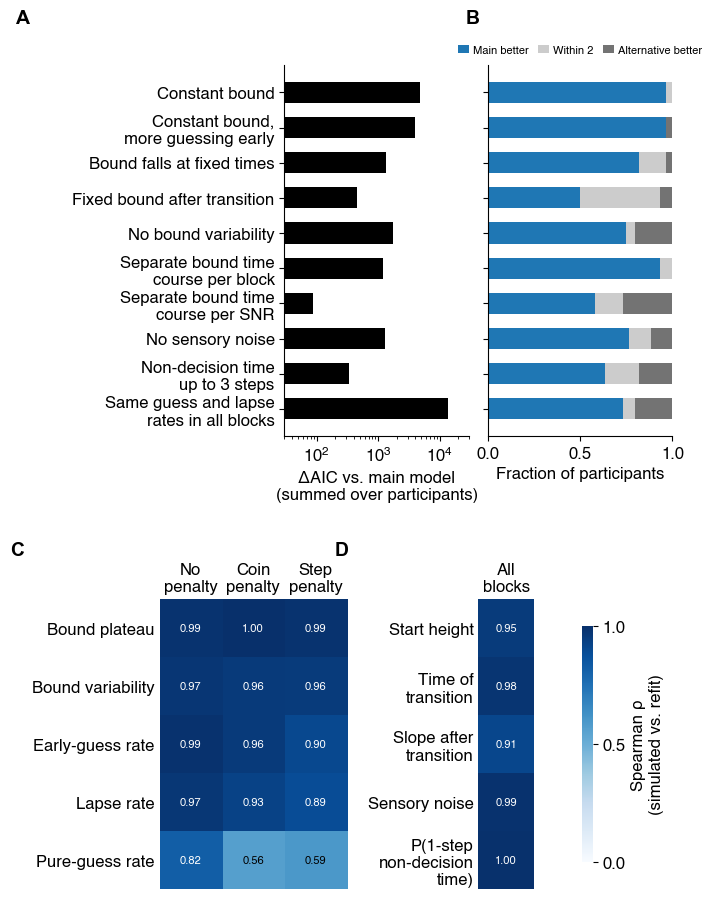

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Figure03_S01.pdf (+ .png)


In [5]:
use_figure_style()

yy = np.arange(len(VARIANTS))

fig = plt.figure(figsize=(17.6 * CM, 23 * CM))
gs_top = gridspec.GridSpec(1, 2, figure=fig, wspace=0.1, left=0.42, right=0.98, bottom=0.53, top=0.94)
ax_a, ax_b = fig.add_subplot(gs_top[0]), fig.add_subplot(gs_top[1])
# heatmaps placed explicitly with cells wider than tall, so the 12-pt column headers fit
ax_c, ax_d = fig.add_axes([0.24, 0.03, 0.27, 0.32]), fig.add_axes([0.70, 0.03, 0.08, 0.32])

ax_a.barh(yy, comp['ΔAIC total'], color='k', height=0.6)
ax_a.set_xscale('log')
ax_a.set_xlim(30, 3e4)
ax_a.set_yticks(yy)
WRAPPED = {'Constant bound, more guessing early': 'Constant bound,\nmore guessing early',
           'Separate bound time course per block': 'Separate bound time\ncourse per block',
           'Separate bound time course per SNR': 'Separate bound time\ncourse per SNR',
           'Non-decision time up to 3 steps': 'Non-decision time\nup to 3 steps',
           'Same guess and lapse rates in all blocks': 'Same guess and lapse\nrates in all blocks'}
ax_a.set_yticklabels([WRAPPED.get(v, v) for v in VARIANTS.values()])
ax_a.invert_yaxis()
ax_a.set_xlabel('ΔAIC vs. main model\n(summed over participants)')

left = np.zeros(len(VARIANTS))
for col, color in (('main better', MODEL_COLOR), ('within 2', '0.8'), ('alternative better', '0.45')):
    w = comp[col].to_numpy()
    ax_b.barh(yy, w, left=left, color=color, height=0.6, label=col.capitalize())
    left += w
ax_b.set_xlim(0, 1)
ax_b.set_xticks([0, 0.5, 1])
ax_b.set_yticks(yy)
ax_b.set_yticklabels([])
ax_b.invert_yaxis()
ax_b.set_xlabel('Fraction of participants')
ax_b.legend(fontsize=FS_INSET, frameon=False, loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=3,
            handlelength=1, columnspacing=0.8, handletextpad=0.4)

for ax in (ax_a, ax_b):
    ax.spines[['top', 'right']].set_visible(False)
CMAP = 'Blues'

def _heatmap(ax, values, ylabels, xlabels):
    im = ax.imshow(values, cmap=CMAP, vmin=0, vmax=1, aspect='auto')
    for (i, j), v in np.ndenumerate(values):
        ax.text(j, i, f'{v:.2f}'.replace('-', '−'), ha='center', va='center', fontsize=FS_INSET,
                color='w' if v > 0.6 else 'k')
    ax.set_yticks(range(len(ylabels)), ylabels)
    ax.set_xticks(range(len(xlabels)), xlabels)
    ax.xaxis.tick_top()
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    return im

_heatmap(ax_c, rho_block.to_numpy(), list(PER_BLOCK.values()), [BLOCK_TITLES[b].replace(' ', '\n') for b in BLOCKS])
im = _heatmap(ax_d, rho_shared.to_numpy()[:, None], ['Start height', 'Time of\ntransition', 'Slope after\ntransition',
                                                      'Sensory noise', 'P(1-step\nnon-decision\ntime)'],
              ['All\nblocks'])
fig.canvas.draw()
pos = ax_d.get_position()
cax = fig.add_axes([0.85, pos.y0 + 0.03, 0.015, pos.height - 0.06])
cb = fig.colorbar(im, cax=cax, ticks=[0, 0.5, 1])
cb.set_label('Spearman ρ\n(simulated vs. refit)')
cb.outline.set_visible(False)
add_panel_label(ax_a, 'A', dx=-1.45, dy=1.15)
add_panel_label(ax_b, 'B', dx=-0.12, dy=1.15)
add_panel_label(ax_c, 'C', dx=-0.8, dy=1.2)
add_panel_label(ax_d, 'D', dx=-2.6, dy=1.2)

out = FIGURES_DIR / 'Figure03_S01.pdf'
fig.savefig(out, dpi=300, bbox_inches='tight')
fig.savefig(out.with_suffix('.png'), dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {out} (+ .png)')